*Author: Cristina. Part of the RSNA Knee Abnormality Detection team project.*

# RSNA Knee MRI — Training Augmentation

This notebook adds some simple augmentation to the knee MRI training data.

I added:
- random rotation up to ±10°
- random shifts up to ±10%
- random zoom from 0.9x to 1.1x
- small contrast changes
- small brightness changes

The augmentation is only used for training.

Validation stays unchanged so the results are consistent.

Things I kept the same:
- no left-right flips
- image shape stays `(1, 224, 224)`
- values stay around `0-1` before normalization

## Data

This loads Alex's processed sagittal MRI data and fixes the `.npy` file paths so they work in this notebook.

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode

In [2]:
BASE_DIR = (
    "/kaggle/input/notebooks/"
    "alextanasescu/02-preprocess-test-alex"
)

MANIFEST_PATH = os.path.join(
    BASE_DIR,
    "manifest_sagittal.csv"
)

IMAGE_DIR = os.path.join(
    BASE_DIR,
    "images_sagittal"
)

manifest = pd.read_csv(MANIFEST_PATH)

manifest["path"] = manifest["StudyInstanceUID"].apply(
    lambda study_id: os.path.join(
        IMAGE_DIR,
        f"{study_id}.npy"
    )
)

print("Manifest shape:", manifest.shape)
manifest.head()

Manifest shape: (4149, 18)


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture,is_labeled,duplicate_of_labeled,SeriesInstanceUID,path,split
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,3.312575e-10,6.904000e-10,9.999999e-01,1.310116e-09,9.999987e-01,8.198703e-10,8.851568e-07,9.857896e-01,5.723617e-10,2.276698e-10,2.194087e-09,1.254501e-07,False,False,1.2.826.0.1.3680043.8.498.12343110195036213483...,/kaggle/input/notebooks/alextanasescu/02-prepr...,train
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.691898e-10,1.394646e-09,3.732246e-09,1.103256e-09,4.204612e-08,2.081525e-08,5.233132e-08,3.293827e-09,1.531719e-09,8.327813e-10,2.228638e-09,3.790109e-09,False,False,1.2.826.0.1.3680043.8.498.72137122913943091996...,/kaggle/input/notebooks/alextanasescu/02-prepr...,train
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,1.179358e-07,1.476140e-08,2.332074e-06,2.114469e-08,9.578994e-01,1.248152e-06,4.687892e-01,1.441848e-08,1.223756e-08,2.614137e-07,4.289095e-07,3.687347e-07,False,False,1.2.826.0.1.3680043.8.498.93288538765996574291...,/kaggle/input/notebooks/alextanasescu/02-prepr...,train
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,4.237782e-07,3.124986e-08,6.972793e-09,1.922222e-05,1.302689e-08,1.204787e-08,9.931201e-08,2.223142e-10,1.438917e-09,1.555837e-09,1.073340e-07,1.008759e-07,False,False,1.2.826.0.1.3680043.8.498.18313433830014722992...,/kaggle/input/notebooks/alextanasescu/02-prepr...,train
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,4.867796e-09,2.123379e-06,1.310148e-09,8.641373e-11,9.746451e-01,1.490282e-07,9.999961e-01,9.755733e-10,1.936264e-09,1.280547e-05,2.547491e-06,1.628052e-06,False,False,1.2.826.0.1.3680043.8.498.70243599053060014636...,/kaggle/input/notebooks/alextanasescu/02-prepr...,train


In [3]:
LABELS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

## Train / Validation Split

For training, I randomly pick a slice from the middle part of the MRI and apply augmentation.

For validation, I always use slice 12 and leave it unchanged so the results are consistent.

In [4]:
train_df = manifest[
    manifest["split"] == "train"
].reset_index(drop=True)

val_df = manifest[
    manifest["split"] == "val"
].reset_index(drop=True)

print("Training studies:", len(train_df))
print("Validation studies:", len(val_df))

Training studies: 4093
Validation studies: 56


## Training Augmentation

I kept the augmentation pretty small so the MRI still looks realistic.

I also avoided horizontal flips because they would swap the medial and lateral sides of the knee.

In [5]:
def augment_mri(img):
    """
    Adds small random changes to the MRI during training.

    Shape: (1, 224, 224)
    Values: 0-1
    """

    # Rotation: ±10°
    angle = np.random.uniform(-10, 10)

    # Translation: ±10% of image width/height
    max_shift = int(0.10 * 224)

    translate = [
        np.random.randint(-max_shift, max_shift + 1),
        np.random.randint(-max_shift, max_shift + 1)
    ]

    # Zoom: 0.9x–1.1x
    scale = np.random.uniform(0.9, 1.1)

    # Apply rotation, shift, and zoom
    img = TF.affine(
        img,
        angle=angle,
        translate=translate,
        scale=scale,
        shear=[0.0, 0.0],
        interpolation=InterpolationMode.BILINEAR
    )

    # Contrast: ×0.9–1.1
    contrast_factor = np.random.uniform(0.9, 1.1)
    img = TF.adjust_contrast(img, contrast_factor)

    # Brightness: ±0.05
    brightness_shift = np.random.uniform(-0.05, 0.05)
    img = img + brightness_shift

    # Keep values between 0 and 1
    img = torch.clamp(img, 0.0, 1.0)

    return img

## Dataset

This class takes one knee MRI at a time, picks a central slice, adds augmentation during training, normalizes it, and returns the image with its labels.

In [6]:
class KneeDataset(Dataset):

    def __init__(self, df, train=False):
        self.df = df.reset_index(drop=True)
        self.train = train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):

        row = self.df.iloc[i]

        # Load MRI volume
        vol = np.load(row["path"])

        # Random middle slice for training, slice 12 for validation
        s = np.random.randint(6, 19) if self.train else 12

        # Shape: (1, 224, 224)
        # Scale pixel values from 0-255 to 0-1.
        img = vol[s:s+1].astype(np.float32) / 255.0
        img = torch.from_numpy(img)

        # Only augment training images
        if self.train:
            img = augment_mri(img)

        # Normalize before sending it to the model
        img = (img - 0.45) / 0.225

        # Get the 12 labels
        y = row[LABELS].values.astype(np.float32)
        y = torch.from_numpy(y)

        return img, y, row["StudyInstanceUID"]

In [7]:
train_dataset = KneeDataset(
    train_df,
    train=True
)

val_dataset = KneeDataset(
    val_df,
    train=False
)

## Sanity Checks

Quick checks to make sure the image shape, labels, and value range are still correct.

In [8]:
train_img, train_y, train_id = train_dataset[0]
val_img, val_y, val_id = val_dataset[0]

print("Train image shape:", train_img.shape)
print("Validation image shape:", val_img.shape)

print("Train label shape:", train_y.shape)
print("Validation label shape:", val_y.shape)

Train image shape: torch.Size([1, 224, 224])
Validation image shape: torch.Size([1, 224, 224])
Train label shape: torch.Size([12])
Validation label shape: torch.Size([12])


In [9]:
row = train_df.iloc[0]

vol = np.load(row["path"])

original = vol[12:13].astype(np.float32) / 255.0
original = torch.from_numpy(original)

augmented = augment_mri(original.clone())

print("Original shape:", original.shape)
print("Augmented shape:", augmented.shape)

print(
    "Original range:",
    original.min().item(),
    "to",
    original.max().item()
)

print(
    "Augmented range:",
    augmented.min().item(),
    "to",
    augmented.max().item()
)

Original shape: torch.Size([1, 224, 224])
Augmented shape: torch.Size([1, 224, 224])
Original range: 0.0 to 1.0
Augmented range: 0.011358540505170822 to 1.0


## Visual Check

Comparing the original slice with 4 augmented versions to make sure they still look normal.

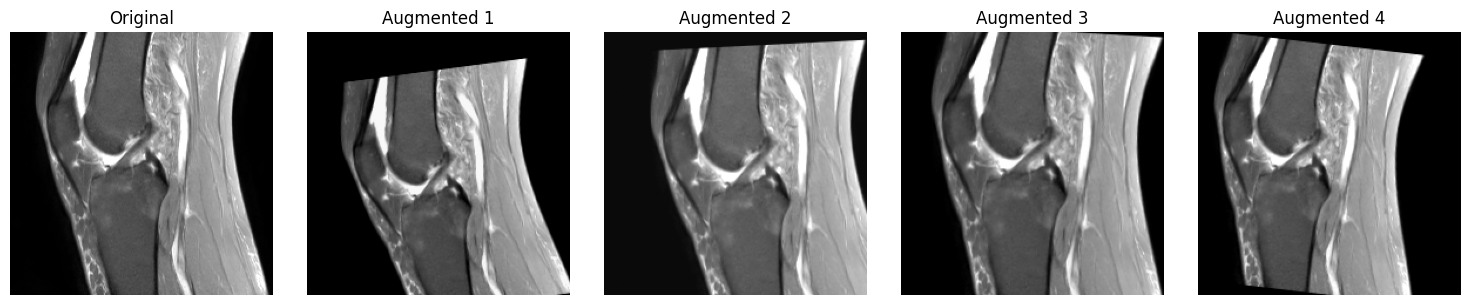

In [10]:
row = train_df.iloc[0]

vol = np.load(row["path"])

original = vol[12:13].astype(np.float32) / 255.0
original = torch.from_numpy(original)

fig, axes = plt.subplots(
    1,
    5,
    figsize=(15, 3)
)

axes[0].imshow(
    original[0],
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0].set_title("Original")
axes[0].axis("off")

for i in range(4):

    augmented = augment_mri(
        original.clone()
    )

    axes[i + 1].imshow(
        augmented[0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i + 1].set_title(
        f"Augmented {i + 1}"
    )

    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

In [11]:
val_img_1, _, _ = val_dataset[0]
val_img_2, _, _ = val_dataset[0]

train_img_1, _, _ = train_dataset[0]
train_img_2, _, _ = train_dataset[0]

print(
    "Validation identical:",
    torch.allclose(
        val_img_1,
        val_img_2
    )
)

print(
    "Training identical:",
    torch.allclose(
        train_img_1,
        train_img_2
    )
)

Validation identical: True
Training identical: False


## Summary

The training pipeline now:

1. Loads the MRI volume
2. Picks a central slice from 6-18 during training
3. Scales the image to 0-1
4. Applies the augmentation
5. Normalizes the image
6. Returns the image, labels, and StudyInstanceUID

Validation still uses slice 12 with no augmentation.